In [1]:
%pip install -q langchain langchain_core langgraph langchain_openai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import dotenv
import os
dotenv.load_dotenv(".env")

True

In [3]:
import dotenv
from typing import TypedDict
from urllib.parse import urlparse
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
from IPython.display import Image, display

In [4]:
from langchain_openai import ChatOpenAI
dotenv.load_dotenv(".env")

raw_base_url = os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")
openrouter_base_url = raw_base_url.strip().strip('"').strip("'")
parsed = urlparse(openrouter_base_url)
if not parsed.scheme or not parsed.netloc:
    openrouter_base_url = "https://openrouter.ai/api/v1"

llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=openrouter_base_url,
    model_name="gpt-4o-mini-2024-07-18",
)

In [5]:
from typing import TypedDict, Literal
from pydantic import BaseModel, Field

class SizeFlag(BaseModel):
    size_issue: Literal["wrong_size", "other"] = Field(..., description="size_issue if the customer says the size, fit or size tag is wrong, otherwise other")

llm_flag = llm.with_structured_output(SizeFlag)

In [6]:
# Flag test
llm_flag.invoke("The tag says 105 but the t-shirt is far too small for my son.")

SizeFlag(size_issue='wrong_size')

In [8]:
class Diagnosis(BaseModel):
    issue_type: Literal["wrong_size_system", "fit_differs_from_chart", "size_info_missing"] = Field(..., description="dThe kind of size problem the customer describes")
    tone: Literal["neutral", "frustrated", "angry"] = Field(..., description="The tone of the customer when describing the size problem")
    urgency: Literal["high", "medium", "low"] = Field(description="How urgently this needs a human")

llm_diagnose = llm.with_structured_output(Diagnosis)

In [9]:
# diagnosis test
llm_diagnose.invoke("The tag says 105 but the t-shirt is far too small for my son. I am very frustrated and need a replacement immediately.")

Diagnosis(issue_type='wrong_size_system', tone='frustrated', urgency='high')

In [20]:
class TriageOutput(TypedDict):
    message: str
    category: Literal["size_issue", "other"]
    diagnosis: dict
    response: str

In [29]:
from langchain_core.prompts import PromptTemplate

def classify(state: TriageOutput) :
    tem = PromptTemplate(
            template="Does this customer message say the size, fit or size tag is wrong? Message: {message}",
            input_variables=["message"]
        )
    chain = tem | llm_flag
    result = chain.invoke({"message": state["message"]})
    return {"category": result.size_issue}

def routine_reply(state: TriageOutput):
    tem = PromptTemplate(
            template="""Write a short, warm reply of 3 sentences to this customer message.
                        Sign off as Hopscotch Support. Do not use placeholders.
                        
                        Message: {message}""",
            input_variables=["message"]
        )
    chain = tem | llm | StrOutputParser()
    result = chain.invoke({"message": state["message"]})
    return {"response": result}

def run_diagnosis(state: TriageOutput):
    tem = PromptTemplate(
            template="Diagnose the size problem in this customer message. Message: {message}",
            input_variables=["message"]
        )
    chain = tem | llm_diagnose
    result = chain.invoke({"message": state["message"]})
    return {"diagnosis": result.model_dump()}

def escalate(state: TriageOutput):
    tem = PromptTemplate(
            template="""A customer reported a size problem.

                        Message: {message}
                        Issue type: {issue_type}
                        Tone: {tone}
                        Urgency: {urgency}

                        Write two parts.
                        CUSTOMER REPLY: a short reply that apologises, does not promise an automatic refund, and says a specialist will review the order.
                        NOTE FOR PPC: two lines that tell the post-production committee what to check.
                        Sign the reply as Hopscotch Support. Do not use placeholders.""",
            input_variables=["message", "issue_type", "tone", "urgency"]
        )
    chain = tem | llm | StrOutputParser()

    diagnosis = state.get("diagnosis", {})
    result = chain.invoke({
        "message": state["message"],
        "issue_type": diagnosis.get("issue_type", "unknown"),
        "tone": diagnosis.get("tone", "neutral"),
        "urgency": diagnosis.get("urgency", "medium"),
    })
    return {"response": result}

def route_by_category(state: TriageOutput) -> Literal["routine_reply", "run_diagnosis"]:
    if state["category"] == "other":
        return "routine_reply"
    else:
        return "run_diagnosis"


In [30]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(TriageOutput)

graph.add_node("classify", classify)
graph.add_node("routine_reply", routine_reply)
graph.add_node("run_diagnosis", run_diagnosis)
graph.add_node("escalate", escalate)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", route_by_category)
graph.add_edge("routine_reply", END)
graph.add_edge("run_diagnosis", "escalate")
graph.add_edge("escalate", END)


workflow = graph.compile()

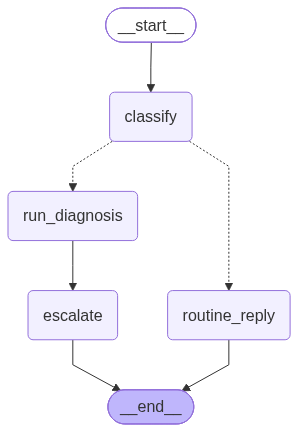

In [26]:
display(Image(workflow.get_graph().draw_mermaid_png()))

In [31]:
final_state = workflow.invoke({"message": "I ordered the green dino tee for my son. The tag says 105 but it is far too small, he is five. This is the third wrong size this month."})
final_state

{'message': 'I ordered the green dino tee for my son. The tag says 105 but it is far too small, he is five. This is the third wrong size this month.',
 'category': 'wrong_size',
 'diagnosis': {'issue_type': 'wrong_size_system',
  'tone': 'frustrated',
  'urgency': 'high'},
 'response': "**CUSTOMER REPLY:**  \nDear Customer,  \n\nWe sincerely apologize for the sizing issues you've experienced with your orders. We understand your frustration, and a specialist will review your order shortly to address the matter.  \n\nThank you for your patience,  \nHopscotch Support  \n\n---\n\n**NOTE FOR PPC:**  \n1. Verify the inventory for the green dino tee to confirm size accuracy.  \n2. Review the customer’s previous orders to identify any patterns or recurring issues with sizes."}

In [32]:
routine_state = workflow.invoke({"message": "Thank you for delivering on time! The tshirt was really good"})
routine_state

{'message': 'Thank you for delivering on time! The tshirt was really good',
 'category': 'other',
 'response': "Hi there! We're so glad to hear that you loved the t-shirt and that it arrived on time. Your satisfaction means a lot to us—thank you for your support!  \n\nBest,  \nHopscotch Support"}